In [82]:
#Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, kruskal
from statsmodels.stats.multitest import multipletests
from astropy.timeseries import LombScargle
from matplotlib.lines import Line2D

In [83]:
ruta = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Parámetros para análisis de Antares\Resultados perfiles halpha útiles 2018-2026.xlsx"
datos = pd.read_excel(ruta)
datos

,Época,Componente,Centro [Å],z,Velocidad obs. [km/s],Velocidad heliocéntrica [km/s],Profundidad / Altura,FWHM [Å],EW [Å],Archivo
0,Julio 24-2018,Emisión Azul Hα,6561.874,-0.000140,-42.83,-65.66,0.10,0.68,0.08,2018-2019
1,Julio 24-2018,Absorción Hα,6562.893,0.000012,3.68,-19.15,0.80,1.08,0.92,2018-2019
2,Julio 24-2018,Absorción Cobalto,6563.829,0.000066,19.71,-3.12,0.56,0.94,0.62,2018-2019
3,Julio 27-2018,Emisión Azul Hα,6561.847,-0.000150,-44.10,-67.97,0.14,0.95,0.17,2018-2019
4,Julio 27-2018,Absorción Hα,6562.896,0.000013,3.82,-20.05,0.79,1.07,0.91,2018-2019
...,...,...,...,...,...,...,...,...,...,...
130,Septiembre 29-2026,Absorción Hα,6562.719,-0.000014,-4.23,-30.81,0.79,1.61,1.39,2024-2026
131,Septiembre 29-2026,Absorción Cobalto,6563.856,0.000070,20.95,-5.63,0.55,1.14,0.77,2024-2026
132,Octubre 16-2026,Emisión Azul Hα,6561.934,-0.000130,-40.10,-61.71,0.65,1.05,0.86,2024-2026
133,Octubre 16-2026,Absorción Hα,6562.575,-0.000036,-10.83,-32.44,0.82,1.61,1.44,2024-2026


In [89]:
meses = {'Julio':7,'Agosto':8,'Septiembre':9,'Octubre':10,'Noviembre':11,'Diciembre':12}

def parsear_fecha(s):

    mes, resto = s.strip().split(' ')
    dia, anio = resto.split('-')
    return pd.Timestamp(year=int(anio), month=meses[mes.capitalize()], day=int(dia))

datos = datos.copy()
datos['Fecha'] = datos['Época'].apply(parsear_fecha)
datos['Año'] = datos['Fecha'].dt.year
datos['t'] = datos['Fecha'].dt.year + (datos['Fecha'].dt.dayofyear - 1) / 365.25

datos = datos.rename(columns={
    'Velocidad heliocéntrica [km/s]': 'V_helio',
    'Profundidad / Altura': 'Amp',
    'FWHM [Å]': 'FWHM',
    'EW [Å]': 'EW',})
    #'Centro [Å]': 'Centro'})

# Nombres cortos de componentes

datos['Comp'] = datos['Componente'].replace({'Absorción Hα': 'Abs Hα', 'Emisión Azul Hα': 'Emi Hα', 'Absorción Cobalto': 'Co I'})
print(datos['Comp'].unique())

variables = ['V_helio', 'Amp', 'FWHM', 'EW']

['Emi Hα' 'Abs Hα' 'Co I']


              var1            var2       rho             p         p_FDR
40         EW_Co I       FWHM_Co I  0.965175  1.138328e-26  7.512965e-25
23      Amp_Emi Hα       EW_Emi Hα  0.961036  1.221387e-25  4.030577e-24
21      Amp_Emi Hα       EW_Abs Hα  0.826173  2.798315e-12  6.156294e-11
51     FWHM_Abs Hα       FWHM_Co I  0.729693  1.296249e-08  2.138811e-07
31       EW_Abs Hα       EW_Emi Hα  0.724616  1.827277e-08  2.394428e-07
47       EW_Emi Hα     FWHM_Emi Hα  0.721984  2.176753e-08  2.394428e-07
50       EW_Emi Hα  V_helio_Emi Hα  0.717427  2.933745e-08  2.766102e-07
32       EW_Abs Hα     FWHM_Abs Hα  0.713154  3.860868e-08  3.185216e-07
24      Amp_Emi Hα     FWHM_Abs Hα  0.706246  5.957236e-08  4.368640e-07
65    V_helio_Co I  V_helio_Emi Hα  0.699479  9.003713e-08  5.778211e-07
63  V_helio_Abs Hα    V_helio_Co I  0.698359  9.630351e-08  5.778211e-07
29      Amp_Emi Hα  V_helio_Emi Hα  0.690647  1.518121e-07  8.349668e-07
39         EW_Co I     FWHM_Abs Hα  0.675013  3.664

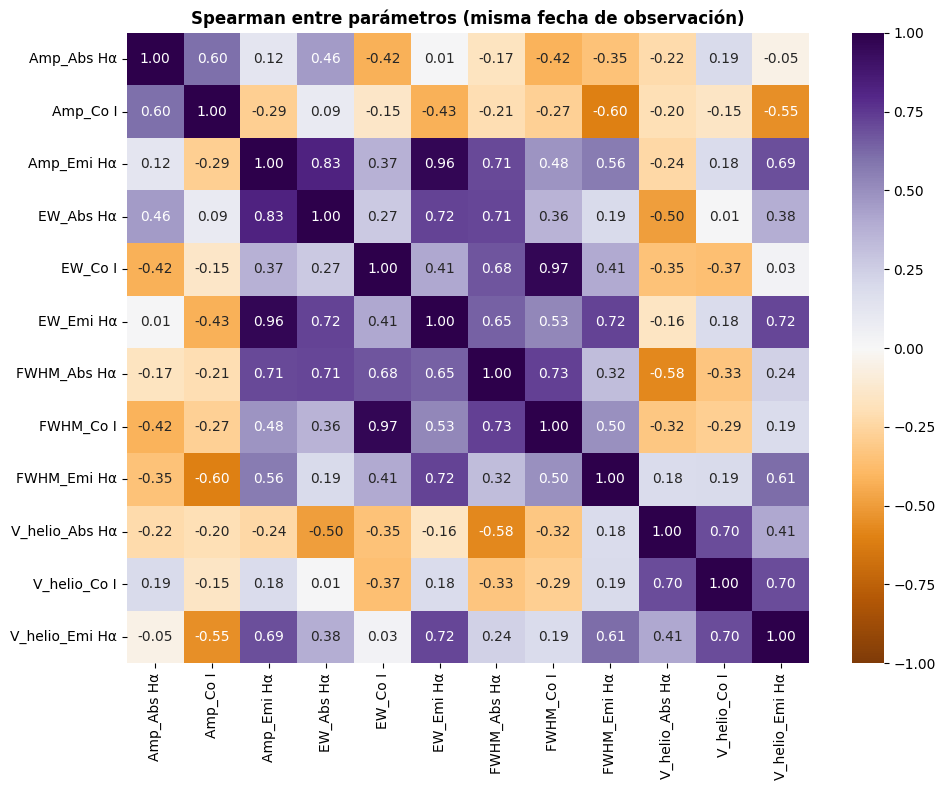

In [90]:
# Una fila por época
ancho = datos.pivot_table(index=['Fecha', 'Año', 't'], columns='Comp', values=variables)
ancho.columns = [f'{v}_{c}' for v, c in ancho.columns]
ancho = ancho.reset_index().sort_values('t')

# Desfase entre la VR de  Abs Hα y Co I
if {'V_helio_AbsHα', 'V_helio_Co'} <= set(ancho.columns):
    ancho['ΔV_AbsHα_Co'] = ancho['V_helio_AbsHα'] - ancho['V_helio_Co']

# Desfase entre la VR de Emi Hα y Co I
if {'V_helio_EmiHα', 'V_helio_Co'} <= set(ancho.columns):
    ancho['ΔV_EmiHα_Co'] = ancho['V_helio_EmiHα'] - ancho['V_helio_Co']

# Desfase entre la VR de las componentes de Emisión y Absorción de Hα
if {'V_helio_EmiHα', 'V_helio_AbsHα'} <= set(ancho.columns):
    ancho['ΔV_EmiHα_AbsHα'] = ancho['V_helio_EmiHα'] - ancho['V_helio_AbsHα']

# Análisis estadístico de Spearman entre parámetros de la misma época
cols = [c for c in ancho.columns if c not in ['Fecha', 'Año', 't']]

def spearman_matriz(d, cols):
    rho = pd.DataFrame(index=cols, columns=cols, dtype=float)
    pv = rho.copy()
    for a in cols:
        for b in cols:
            if a == b:
                rho.loc[a, b] = 1.0
                continue
            sub = d[[a, b]].dropna()
            if len(sub) >= 5:
                r, p = spearmanr(sub[a], sub[b])
                rho.loc[a, b], pv.loc[a, b] = r, p
    return rho, pv

rho, pv = spearman_matriz(ancho, cols)

# Corrección por comparaciones múltiples (FDR) sobre el triángulo superior
iu = np.triu_indices(len(cols), k=1)
pvals = pv.values[iu]
ok = ~np.isnan(pvals)
p_fdr = np.full_like(pvals, np.nan)
p_fdr[ok] = multipletests(pvals[ok], method='fdr_bh')[1]

tabla = pd.DataFrame({'var1': np.array(cols)[iu[0]], 'var2': np.array(cols)[iu[1]],
                      'rho': rho.values[iu], 'p': pvals, 'p_FDR': p_fdr})
tabla = tabla.dropna().sort_values('p')
print(tabla[tabla['p_FDR'] < 0.05])   # Riesgo de falsos positivos < 5%

plt.figure(figsize=(10, 8))
sns.heatmap(rho.astype(float), annot=True, fmt='.2f', cmap='PuOr', vmin=-1, vmax=1)
plt.title('Spearman entre parámetros (misma fecha de observación)', fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

          variable   n    ρ vs t             p         p_FDR
7        FWHM_Co I  45  0.786995  1.452148e-10  1.742578e-09
6      FWHM_Abs Hα  45  0.741241  5.765772e-09  3.459463e-08
4          EW_Co I  45  0.681654  2.536736e-07  1.014694e-06
5        EW_Emi Hα  45  0.670029  4.799836e-07  1.439951e-06
2       Amp_Emi Hα  45  0.611190  8.214147e-06  1.971395e-05
8      FWHM_Emi Hα  45  0.573773  3.780782e-05  7.561564e-05
1         Amp_Co I  45 -0.538100  1.375901e-04  2.358688e-04
0       Amp_Abs Hα  45 -0.497048  5.139911e-04  7.709866e-04
3        EW_Abs Hα  45  0.410285  5.122310e-03  6.829747e-03
11  V_helio_Emi Hα  45  0.333070  2.537215e-02  3.044658e-02
10    V_helio_Co I  45 -0.272584  7.005324e-02  7.642172e-02
9   V_helio_Abs Hα  45 -0.250198  9.739244e-02  9.739244e-02


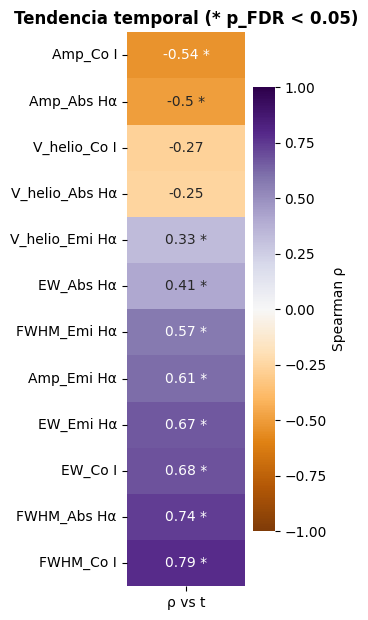

In [91]:
# Tendencia temporal de cada parámetro (Spearman vs t)

res_t = []

for c in cols:
    sub = ancho[['t', c]].dropna()
    if len(sub) >= 5:
        r, p = spearmanr(sub['t'], sub[c])
        res_t.append((c, len(sub), r, p))

res_t = pd.DataFrame(res_t, columns=['variable', 'n', 'ρ vs t', 'p'])
res_t['p_FDR'] = multipletests(res_t['p'], method='fdr_bh')[1]
print(res_t.sort_values('p'))

# Orden por ρ y marca de significancia según p_FDR
tab = res_t.set_index('variable').sort_values('ρ vs t')
etiquetas = tab['ρ vs t'].round(2).astype(str) + np.where(tab['p_FDR'] < 0.05, ' *', '')

plt.figure(figsize=(3.5, 0.4 * len(tab) + 1.5))
sns.heatmap(tab[['ρ vs t']], annot=etiquetas.to_frame(), fmt='',
            cmap='PuOr', vmin=-1, vmax=1, cbar_kws={'label': 'Spearman ρ'})
plt.title('Tendencia temporal (* p_FDR < 0.05)', fontsize=12, fontweight="bold")
plt.ylabel('')
plt.tight_layout(); plt.show()

In [93]:
colores = {"Emisión Azul Hα": "turquoise", "Absorción Hα": "deepskyblue", "Absorción Cobalto": "purple"}
marcadores = {"Emisión Azul Hα": "o", "Absorción Hα": "s", "Absorción Cobalto": "^"}

orden = ['Abs Hα', 'Emi Hα', 'Co I']
   parametro    Comp  n_años          H             p         p_FDR
0    V_helio  Abs Hα       4  27.213994  5.309481e-06  2.123792e-05
1    V_helio  Emi Hα       4  36.586352  5.628495e-08  6.754194e-07
2    V_helio    Co I       4  34.486058  1.564212e-07  9.385275e-07
3        Amp  Abs Hα       4  22.810837  4.422021e-05  7.580608e-05
4        Amp  Emi Hα       4  23.279080  3.531953e-05  7.580608e-05
5        Amp    Co I       4  22.347179  5.523245e-05  8.284867e-05
6       FWHM  Abs Hα       4  21.647768  7.721832e-05  1.029578e-04
7       FWHM  Emi Hα       4  22.956739  4.123022e-05  7.580608e-05
8       FWHM    Co I       4  20.502586  1.335297e-04  1.602357e-04
9         EW  Abs Hα       4  13.071099  4.485345e-03  4.485345e-03
10        EW  Emi Hα       4  24.418533  2.042611e-05  6.127833e-05
11        EW    Co I       4  16.615947  8.476191e-04  9.246753e-04


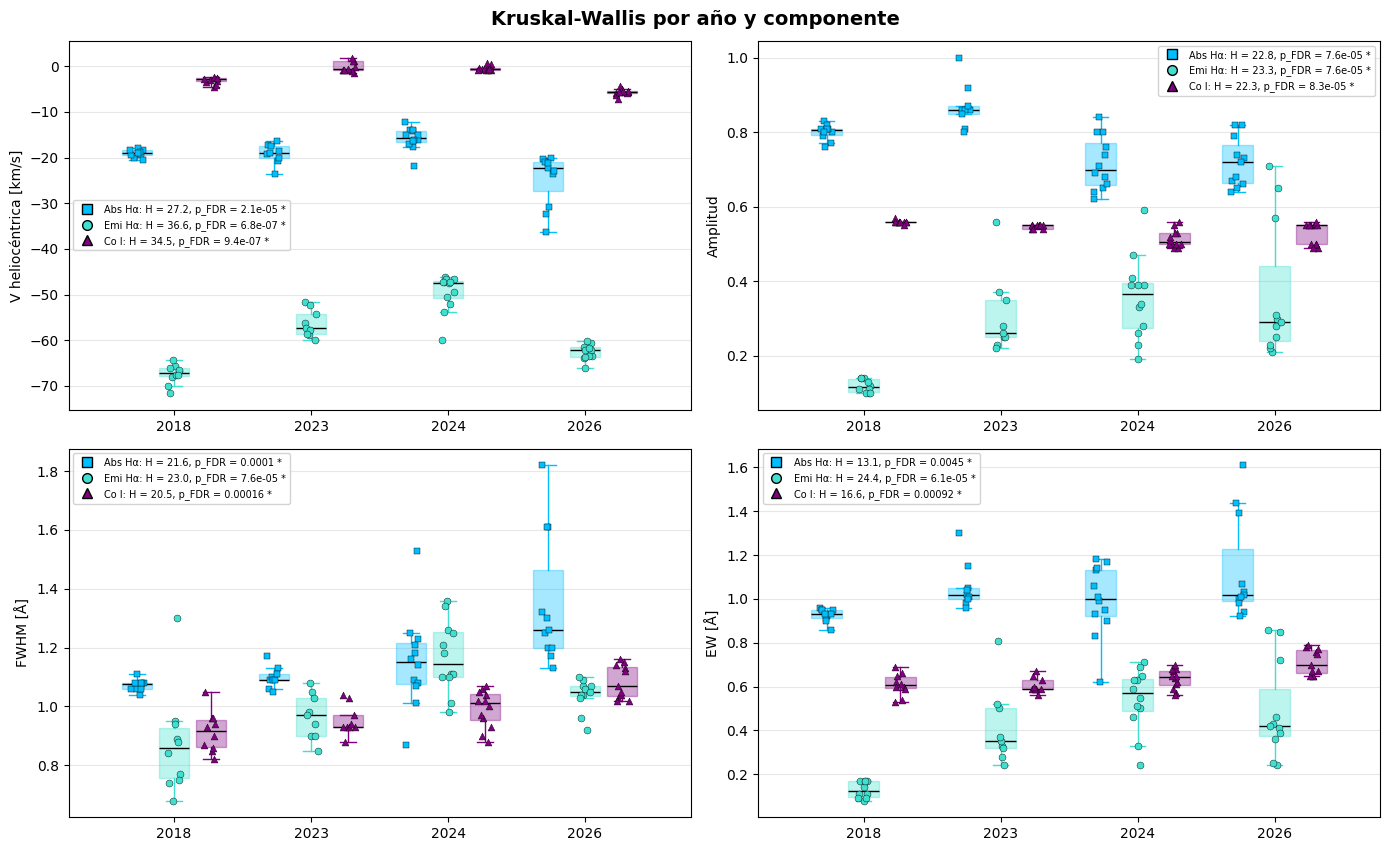

In [114]:
parametros_kw = {'V_helio': 'V heliocéntrica [km/s]', 'Amp': 'Amplitud', 'FWHM': 'FWHM [Å]', 'EW': 'EW [Å]'}

nombres = datos['Comp'].unique().tolist()
orden = [next(n for n in nombres if n.startswith(p)) for p in ('Abs', 'Emi', 'Co')]
print('orden =', orden)

nombre_completo = datos.drop_duplicates('Comp').set_index('Comp')['Componente'].to_dict()

col_c = {c: colores.get(nombre_completo[c], 'gray') for c in orden}
mar_c = {c: marcadores.get(nombre_completo[c], 'o') for c in orden}
desp  = dict(zip(orden, (-0.27, 0.0, 0.27)))


col_c = {c: colores.get(nombre_completo[c], 'gray') for c in orden}
mar_c = {c: marcadores.get(nombre_completo[c], 'o') for c in orden}

# Kruskal-Wallis por año y componente

filas = []

for v in parametros_kw:
    for c in orden:
        d = datos[datos['Comp'] == c].dropna(subset=[v])
        grupos = [g[v].values for _, g in d.groupby('Año') if len(g) >= 3]
        if len(grupos) >= 2:
            H, p = kruskal(*grupos)
            filas.append((v, c, len(grupos), H, p))

res_kw2 = pd.DataFrame(filas, columns=['parametro', 'Comp', 'n_años', 'H', 'p'])
res_kw2['p_FDR'] = multipletests(res_kw2['p'], method='fdr_bh')[1]

print(res_kw2)

# Figura de Bigotes

anios = sorted(a for a, g in datos.groupby('Año')
               if (g.groupby('Comp').size() >= 3).any())
x0 = {a: i for i, a in enumerate(anios)}
rng = np.random.default_rng(0)

fig, axs = plt.subplots(2, 2, figsize=(14, 9))

for ax, (v, etiqueta) in zip(axs.ravel(), parametros_kw.items()):
    handles = []
    for c in orden:
        d = datos[(datos['Comp'] == c) & (datos['Año'].isin(anios))].dropna(subset=[v])
        for a, g in d.groupby('Año'):
            pos = x0[a] + desp[c]
            if len(g) >= 3:
                ax.boxplot(g[v].values, positions=[pos], widths=0.22, showfliers=False,
                           patch_artist=True,
                           boxprops=dict(facecolor=col_c[c], alpha=0.35, edgecolor=col_c[c]),
                           medianprops=dict(color='k'),
                           whiskerprops=dict(color=col_c[c]), capprops=dict(color=col_c[c]))
            ax.scatter(pos + rng.uniform(-0.05, 0.05, len(g)), g[v], color=col_c[c],
                       marker=mar_c[c], s=25, edgecolor='k', linewidth=0.3, zorder=3)
            

        f = res_kw2[(res_kw2['parametro'] == v) & (res_kw2['Comp'] == c)]
        if len(f):
            f = f.iloc[0]
            txt = f"{c}: H = {f['H']:.1f}, p_FDR = {f['p_FDR']:.2g}{' *' if f['p_FDR'] < 0.05 else ''}"
        else:
            txt = f"{c}: sin prueba (n insuficiente)"
        handles.append(Line2D([], [], color=col_c[c], marker=mar_c[c], ls='',
                              markeredgecolor='k', markersize=7, label=txt))
        
    ax.set_xticks(range(len(anios))); ax.set_xticklabels(anios)
    ax.set_ylabel(etiqueta); ax.grid(alpha=0.3, axis='y')
    ax.legend(handles=handles, fontsize=7, loc='best', framealpha=0.85)
    

fig.suptitle('Kruskal-Wallis por año y componente', fontsize=14, fontweight='bold', y = 0.94)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('KW_por_anio_y_componente.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ---------- 7. Periodograma Lomb-Scargle (velocidades) ----------
fig, ax = plt.subplots(figsize=(9, 4))
for c in ['V_helio_Co', 'V_helio_AbsHa', 'dV_AbsHa_Co']:
    if c in ancho:
        sub = ancho[['t', c]].dropna()
        if len(sub) > 10:
            freq, power = LombScargle(sub['t'], sub[c]).autopower(
                minimum_frequency=1/(sub['t'].max() - sub['t'].min()),
                maximum_frequency=2, samples_per_peak=10)
            ax.plot(1/freq, power, label=c)
            print(c, 'periodo del pico principal: %.2f años' % (1/freq[np.argmax(power)]))
ax.set_xscale('log'); ax.set_xlabel('Periodo [años]'); ax.set_ylabel('Potencia'); ax.legend()
plt.tight_layout(); plt.show()

# ---------- 8. Correlación con desfase (dV vs. V del Cobalto) ----------
# Interpolamos la serie del Cobalto y buscamos el retardo que maximiza Spearman con dV
if 'dV_AbsHa_Co' in ancho:
    s = ancho[['t', 'V_helio_Co', 'dV_AbsHa_Co']].dropna()
    retardos = np.arange(0, 3.01, 0.1)  # años; ajusta según tu ciclo
    out = []
    for lag in retardos:
        vco = np.interp(s['t'] - lag, s['t'], s['V_helio_Co'])
        mask = (s['t'] - lag) >= s['t'].min()
        if mask.sum() >= 8:
            r, p = spearmanr(vco[mask], s['dV_AbsHa_Co'][mask])
            out.append((lag, r, p, mask.sum()))
    out = pd.DataFrame(out, columns=['lag_años', 'rho', 'p', 'n'])
    print(out.loc[out['rho'].abs().idxmax()])
    plt.plot(out['lag_años'], out['rho']); plt.xlabel('Retardo [años]'); plt.ylabel('Spearman ρ')
    plt.show()